# 03 - Model Evaluation

**Task.** Predict whether a diabetic inpatient is readmitted within 30 days (`target = 1`).
**Final model under evaluation.** Tuned CatBoost, decision threshold chosen on a patient-grouped validation split.

This notebook reads the saved test predictions (`outputs/test_predictions.csv`) and never feeds test information back into modeling. The only model it may re-fit is the final Tuned CatBoost on the *fit* part of the training set, to obtain **validation** scores (cached in `outputs/evaluation/model_predictions.csv`); these scores are used to choose operating thresholds without looking at the test set. Every table is written to `outputs/evaluation/tables/` and every figure to `outputs/evaluation/figures/`.

**Uncertainty.** The test set has 19,802 encounters but only about 14,000 patients, and encounters of the same patient are correlated. All confidence intervals and all p-values for differences between models therefore come from a **patient-level cluster bootstrap** (patients, not encounters, are resampled; B = 2,000, and B = 1,000 for subgroups). DeLong's method is shown only as a reference that assumes independent encounters.

| Section | Question answered |
|---|---|
| 1 | How good is the final model, with uncertainty? |
| 2 | Why these metrics (accuracy trap) |
| 3 | Is it significantly better than the other models? (same test rows, paired patient-level bootstrap) |
| 4 | Which threshold should a hospital use? (thresholds chosen on validation, cost-sensitive analysis, decision curve) |
| 5 | Who should the hospital call first? (Recall@Top-k, gain / lift) |
| 6 | What do missed readmissions and false alarms look like? (error analysis) |
| 7 | Is the model calibrated, and does it work across subgroups? |
| 8 | How do we compare with published / public baselines? |

In [4]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

# locate repo root (works whether VS Code starts the kernel in notebooks/ or in the repo root)
ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import evaluation as ev
from compare_models import add_advanced_features, build_preprocessor, build_candidates, run as run_refit

FIG = ROOT / "outputs" / "evaluation" / "figures"; TAB = ROOT / "outputs" / "evaluation" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
N_BOOT, N_BOOT_SG, SEED = 2000, 1000, 42      # patient-level resamples: models / subgroups

pred = pd.read_csv(ROOT / "outputs" / "test_predictions.csv")
test = pd.read_csv(ROOT / "data" / "test_clean.csv")
meta = json.load(open(ROOT / "outputs" / "best_params.json"))
THR = meta["threshold"]
y, p = pred["y_true"].to_numpy(), pred["probability"].to_numpy()

# integrity checks: predictions must be row-aligned with the test features
assert len(pred) == len(test), "row count mismatch"
assert (test["target"].to_numpy() == y).all(), "predictions are not aligned with test_clean.csv"


def rebuild_test_groups(root, test_df):
    """Patient ids of the test rows, rebuilt IN MEMORY with the same filter + split as 01_data_eda.
    Nothing is written to disk and no other notebook is touched; the assertions guarantee that the
    rebuilt rows are aligned one-to-one with data/test_clean.csv."""
    from sklearn.model_selection import GroupShuffleSplit
    raw = pd.read_csv(root / "input" / "diabetic_data.csv").replace("?", np.nan)
    raw = raw[~raw["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])]      # expired / hospice
    _, idx = next(GroupShuffleSplit(test_size=0.2, n_splits=1, random_state=42).split(raw, groups=raw["patient_nbr"]))
    sub = raw.iloc[idx].reset_index(drop=True)
    
    assert len(sub) == len(test_df), "rebuilt test set has a different size"
    assert (sub["readmitted"].eq("<30").astype(int).to_numpy() == test_df["target"].to_numpy()).all(), "target not aligned"
    
    # Chỉ đối chiếu các cột thông tin gốc chưa bị thay đổi qua bước Data Cleaning/EDA
    for c in ["age", "gender"]:
        assert (sub[c].astype(str).to_numpy() == test_df[c].astype(str).to_numpy()).all(), f"{c} not aligned"
        
    return sub["patient_nbr"].to_numpy()


# use data/test_patient_groups.csv if the EDA notebook ever saves it, otherwise rebuild the ids in memory
gfile = ROOT / "data" / "test_patient_groups.csv"
GROUPS = pd.read_csv(gfile)["patient_nbr"].to_numpy() if gfile.exists() else rebuild_test_groups(ROOT, test)
assert len(GROUPS) == len(y)
n_pat = len(set(GROUPS))
print(f"Test encounters: {len(y):,} | positives: {y.sum():,} ({y.mean():.2%}) | threshold: {THR:.4f}")
print(f"Bootstrap type : cluster (by patient) - {n_pat:,} patients, {len(y) / n_pat:.2f} encounters per patient; "
      f"B = {N_BOOT:,} (subgroups: {N_BOOT_SG:,})")

Test encounters: 19,802 | positives: 2,216 (11.19%) | threshold: 0.1436
Bootstrap type : cluster (by patient) - 13,998 patients, 1.41 encounters per patient; B = 2,000 (subgroups: 1,000)


In [5]:
# ---- helpers used below (kept in the notebook so that src/ does not need to change) -------------------------
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import GroupShuffleSplit

GI = ev._group_index(GROUPS)                  # one array of row indices per test patient
METRICS = ["ROC-AUC", "AP (PR-AUC)", "Recall", "Precision", "Specificity", "F1"]


def _boot_metrics(yb, pb, thr):
    pred_ = pb >= thr
    tp = int((pred_ & (yb == 1)).sum()); fp = int((pred_ & (yb == 0)).sum())
    fn = int((~pred_ & (yb == 1)).sum()); tn = int((~pred_ & (yb == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    return {"ROC-AUC": roc_auc_score(yb, pb), "AP (PR-AUC)": average_precision_score(yb, pb),
            "Recall": rec, "Precision": prec, "Specificity": tn / (tn + fp) if tn + fp else 0.0,
            "F1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0}


def cluster_bootstrap_models(y, proba, thr, gi, n_boot, seed=42):
    """Patient-level bootstrap shared by all models: every resample (patients drawn with replacement)
    is scored for every model, so differences between models are paired."""
    rng, y = np.random.default_rng(seed), np.asarray(y)
    draws = {m: {k: [] for k in METRICS} for m in proba}
    for _ in range(n_boot):
        ix = ev._resample_indices(len(y), rng, gi)
        yb = y[ix]
        if yb.min() == yb.max():
            continue
        for m, pr in proba.items():
            for k, v in _boot_metrics(yb, pr[ix], thr[m]).items():
                draws[m][k].append(v)
    return {m: {k: np.asarray(v) for k, v in d.items()} for m, d in draws.items()}


def _boot_p(d):
    B = len(d)
    return float(min(1.0, 2 * min(((d <= 0).sum() + 1) / (B + 1), ((d >= 0).sum() + 1) / (B + 1))))


def pairwise_cluster(y, proba, thr, draws, reference):
    """Reference model minus every other model, per metric: estimate, 95% percentile CI and two-sided
    bootstrap p-value from the shared patient-level resamples; Holm-adjusted across models within a metric."""
    tests = [("ΔAUC", "ROC-AUC"), ("ΔAP", "AP (PR-AUC)"), ("ΔF1", "F1"), ("ΔRecall", "Recall"), ("ΔSpecificity", "Specificity")]
    ref_est = _boot_metrics(np.asarray(y), proba[reference], thr[reference])
    rows = []
    for name, pr in proba.items():
        if name == reference:
            continue
        est = _boot_metrics(np.asarray(y), pr, thr[name])
        row = {"Model": name}
        for lab, key in tests:
            d = draws[reference][key] - draws[name][key]
            row[lab] = ref_est[key] - est[key]
            row[lab + " 95% CI"] = f"[{np.quantile(d, .025):+.4f}, {np.quantile(d, .975):+.4f}]"
            row["p " + lab[1:]] = _boot_p(d)
        row["p DeLong (indep., reference)"] = ev.delong_test(y, proba[reference], pr)["p"]
        rows.append(row)
    df = pd.DataFrame(rows)
    for col in [c for c in df.columns if c.startswith("p ")]:
        df[col + " (Holm)"] = ev.holm_correction(df[col].values)
    return df


def subgroup_report_cluster(df, y, p, thr, col, groups, n_boot, seed=42, min_n=500, min_pos=50):
    """ev.subgroup_report, but AUC / Recall / Prevalence intervals come from a patient-level bootstrap inside
    each group (reliable groups only; the others keep their estimates and get no interval)."""
    rep = ev.subgroup_report(df, y, p, thr, col, min_n=min_n, min_pos=min_pos)
    y, p, groups = np.asarray(y), np.asarray(p), np.asarray(groups)
    idx = df.groupby(col, observed=True).indices
    rng = np.random.default_rng(seed)
    for k, row in rep.iterrows():
        for c in ["AUC low", "AUC high", "Recall low", "Recall high", "Prev low", "Prev high"]:
            rep.at[k, c] = np.nan
        if not row["Reliable"]:
            continue
        ix = idx[row["Group"]]
        yy, pp, gi = y[ix], p[ix], ev._group_index(groups[ix])
        auc, rec, prv = [], [], []
        for _ in range(n_boot):
            jx = ev._resample_indices(len(ix), rng, gi)
            yb, pb = yy[jx], pp[jx]
            if yb.min() == yb.max():
                continue
            auc.append(roc_auc_score(yb, pb)); rec.append(((pb >= thr) & (yb == 1)).sum() / (yb == 1).sum()); prv.append(yb.mean())
        for nm, d in [("AUC", auc), ("Recall", rec), ("Prev", prv)]:
            rep.at[k, f"{nm} low"], rep.at[k, f"{nm} high"] = np.quantile(d, [0.025, 0.975])
    return rep


# ---- validation scores of the final model: used to choose thresholds WITHOUT touching the test set -------------
VAL_CACHE = ROOT / "outputs" / "evaluation" / "val_predictions_tuned_catboost.csv"


def get_val_predictions():
    """Final Tuned CatBoost fitted on the 'fit' part of train (same patient-grouped 80/20 split, seed 42, as the
    modeling notebook) and scored on the validation part. Cached after the first run."""
    if VAL_CACHE.exists():
        print(f"[cache] {VAL_CACHE.relative_to(ROOT)} exists - skipping refit (delete it to recompute)")
        return pd.read_csv(VAL_CACHE)
    train = pd.read_csv(ROOT / "data" / "train_clean.csv")
    grp = pd.read_csv(ROOT / "data" / "train_patient_groups.csv")["patient_nbr"].to_numpy()
    X, yt = add_advanced_features(train).drop(columns="target"), train["target"]
    fit_idx, val_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(X, yt, grp))
    pipe = build_candidates(build_preprocessor(X), meta["best_params"])["Tuned CatBoost"]
    m = clone(pipe).fit(X.iloc[fit_idx], yt.iloc[fit_idx])
    out = pd.DataFrame({"y_true": yt.iloc[val_idx].to_numpy(), "probability": m.predict_proba(X.iloc[val_idx])[:, 1]})
    out.to_csv(VAL_CACHE, index=False)
    print(f"[fit] validation predictions written to {VAL_CACHE.relative_to(ROOT)}")
    return out


def val_cost_threshold(yv, pv, k, n=400):
    """Cost-optimal threshold for FN:FP = k, searched on the validation scores only."""
    grid = np.unique(np.round(np.quantile(pv, np.linspace(0.01, 0.995, n)), 5))
    c = ev.cost_curve(yv, pv, k, grid)
    return float(c.loc[c["Cost / patient"].idxmin(), "Threshold"])

## 1. Headline performance of the final model

All intervals are 95% percentile **patient-level cluster bootstrap** CIs (B = 2,000). DeLong's ROC-AUC interval is printed only as a reference: it assumes independent encounters, so it is a little too narrow.

In [6]:
ci = ev.bootstrap_ci(y, p, THR, metrics=["ROC-AUC", "AP (PR-AUC)", "Precision", "Recall", "Specificity", "F1"],
                     n_boot=N_BOOT, groups=GROUPS, seed=SEED)
ci["Estimate [95% CI]"] = ci.apply(ev.fmt_ci, axis=1)
r_auc = ci[ci["Metric"] == "ROC-AUC"].iloc[0]
auc, lo, hi = float(r_auc["Estimate"]), float(r_auc["CI low"]), float(r_auc["CI high"])      # patient-level CI (used downstream)
dl_auc, dl_lo, dl_hi = ev.delong_auc_ci(y, p)                                               # reference only
tm = ev.threshold_metrics(y, p, THR)
display(ci[["Metric", "Estimate [95% CI]"]].set_index("Metric"))
print(f"ROC-AUC = {auc:.3f}, patient-level bootstrap 95% CI {lo:.3f}-{hi:.3f}  |  DeLong (assumes independent encounters, reference only): {dl_lo:.3f}-{dl_hi:.3f}")
print(f"Confusion counts at threshold {THR:.3f}: TP={tm['TP']}, FP={tm['FP']}, FN={tm['FN']}, TN={tm['TN']}")
print(f"MCC = {tm['MCC']:.3f} | Balanced accuracy = {tm['Balanced Acc']:.3f} | NPV = {tm['NPV']:.3f} | Flagged = {tm['Flagged %']:.1f}% of patients")
ci.to_csv(TAB / "01_headline_metrics_ci.csv", index=False)

,Estimate [95% CI]
Metric,
ROC-AUC,"0.676 [0.662, 0.691]"
AP (PR-AUC),"0.245 [0.222, 0.269]"
Precision,"0.215 [0.200, 0.231]"
Recall,"0.430 [0.402, 0.459]"
Specificity,"0.802 [0.795, 0.810]"
F1,"0.286 [0.267, 0.305]"


ROC-AUC = 0.676, patient-level bootstrap 95% CI 0.662-0.691  |  DeLong (assumes independent encounters, reference only): 0.664-0.689
Confusion counts at threshold 0.144: TP=952, FP=3478, FN=1264, TN=14108
MCC = 0.175 | Balanced accuracy = 0.616 | NPV = 0.918 | Flagged = 22.4% of patients


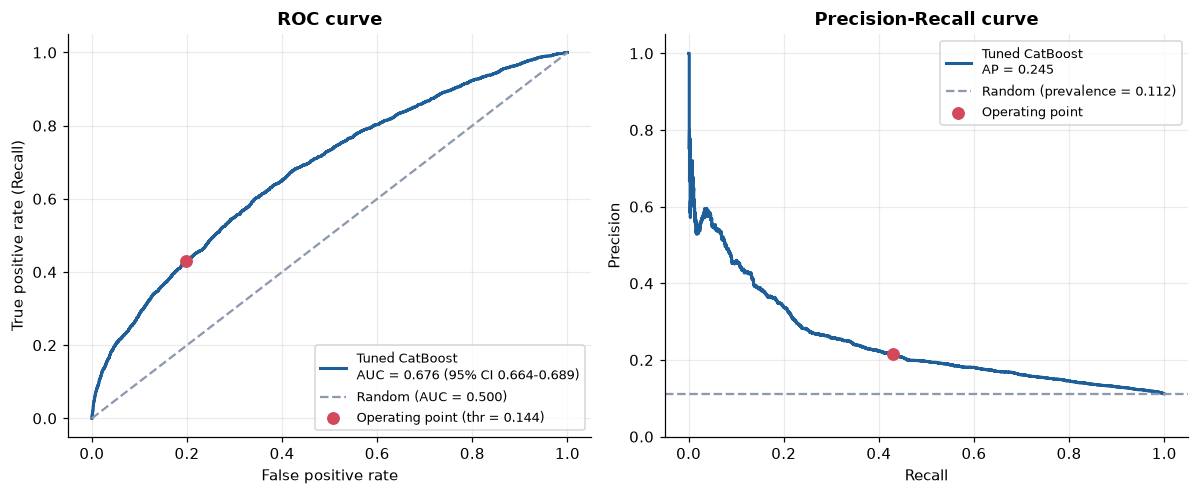

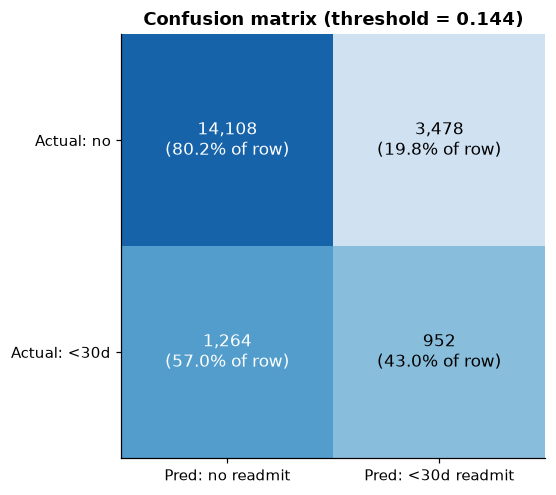

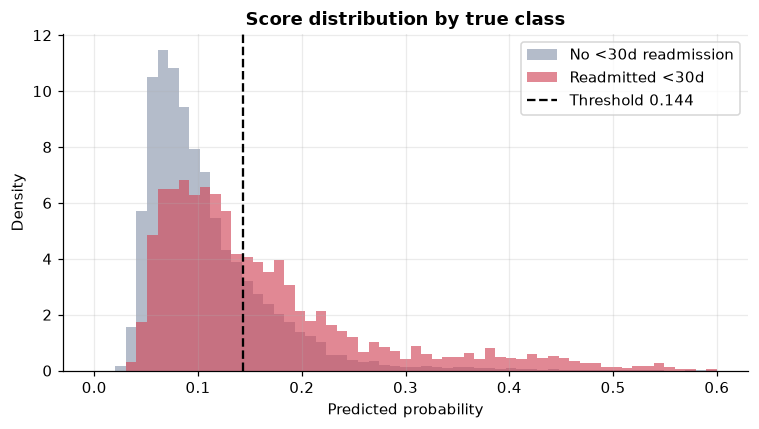

In [7]:
ev.plot_roc_pr(y, p, THR, FIG / "01_roc_pr.png"); plt.show()
ev.plot_confusion(y, p, THR, FIG / "01_confusion_matrix.png"); plt.show()
ev.plot_score_distribution(y, p, THR, FIG / "01_score_distribution.png"); plt.show()

## 2. Why accuracy is the wrong headline metric

With 11% positives, a model that never flags anyone is 89% accurate and useless. Hospitals care about
**catching readmissions (Recall)** without drowning staff in false alarms **(Precision)**, and about the *ranking* quality that is
independent of any threshold (**ROC-AUC, Average Precision**). Average Precision is the main selection metric because
its random-classifier value equals the prevalence, so its lift over chance is easy to interpret.

In [8]:
prev = y.mean()
ref = pd.DataFrame([
    {"Classifier": "Flag nobody (majority class)",   "Accuracy": 1 - prev, "Recall": 0.0, "Precision": np.nan, "F1": 0.0, "AP": prev, "ROC-AUC": 0.5},
    {"Classifier": "Flag everybody",                 "Accuracy": prev,     "Recall": 1.0, "Precision": prev,   "F1": 2*prev/(1+prev), "AP": prev, "ROC-AUC": 0.5},
    {"Classifier": "Tuned CatBoost (final model)",   "Accuracy": tm["Accuracy"], "Recall": tm["Recall"], "Precision": tm["Precision"],
     "F1": tm["F1"], "AP": ev.ranking_metrics(y, p)["AP (PR-AUC)"], "ROC-AUC": auc},
]).set_index("Classifier")
display(ref.round(3)); ref.to_csv(TAB / "02_naive_reference.csv")
r = ev.ranking_metrics(y, p)
print(f"AP is {r['AP / prevalence']:.2f}x the random baseline ({prev:.3f}).")

,Accuracy,Recall,Precision,F1,AP,ROC-AUC
Classifier,,,,,,
Flag nobody (majority class),0.888,0.00,NaN,0.000,0.112,0.500
Flag everybody,0.112,1.00,0.112,0.201,0.112,0.500
Tuned CatBoost (final model),0.761,0.43,0.215,0.286,0.245,0.676


AP is 2.19x the random baseline (0.112).


## 3. Model comparison on the *same* test rows + statistical testing

**Protocol.** Every candidate is re-fit with the identical procedure used for the final model (`src/compare_models.py`):
fit on a patient-grouped 80% of train -> choose the F1-optimal threshold on the remaining 20% -> refit on all of train -> score the test set.
Hence each model is judged at *its own* validation-selected threshold, and no test information is used for any choice.

**Uncertainty and tests (all on the shared test set).** Test encounters from the same patient are correlated, so every interval and p-value below comes from one **patient-level cluster bootstrap**:
in each of B = 2,000 resamples, patients are drawn with replacement and *all* nine models are scored on that same resample, which pairs the comparisons.
For ROC-AUC, AP, F1, Recall and Specificity the difference "Tuned CatBoost minus the other model" is summarised by a 95% percentile interval and a two-sided bootstrap p-value, Holm-adjusted across the 8 comparisons within each metric.
DeLong's test is kept as a reference column only, because it assumes independent encounters. The exact McNemar test used in an earlier draft is dropped for the same reason; the paired Recall and Specificity differences answer the same question (different operating points) at patient level.

*Why not a t-test on CV folds?* The team's CV uses only 3 folds, so the Nadeau-Bengio corrected t-test has 2 degrees of freedom and almost no power
(a Wilcoxon test on 3 folds cannot even reach p < 0.25). `ev.corrected_resampled_ttest` is provided if you later run repeated CV.

In [9]:
mp = run_refit(ROOT)                                    # uses the cached file if it exists
THR_M = json.load(open(ROOT / "outputs/evaluation/model_thresholds.json"))
assert (mp["y_true"].to_numpy() == y).all()
diff = np.abs(mp["Tuned CatBoost"] - p).max()
print(f"Sanity check - re-fit Tuned CatBoost vs team's saved predictions: max |diff| = {diff:.2e}")
print("(identical to the bit: CatBoost with a fixed seed is deterministic, so the cached column is a faithful re-fit)" if diff == 0 else "WARNING: the re-fit differs from the saved predictions - check library versions") 

proba = {c: mp[c].to_numpy() for c in mp.columns if c != "y_true"}
proba["Tuned CatBoost"] = p                              # canonical predictions from the modeling notebook
thr_m = dict(THR_M); thr_m["Tuned CatBoost"] = THR

[cache] /Users/vianhbui/Downloads/diabetes-readmission-prediction/outputs/evaluation/model_predictions.csv exists - skipping refit (use --force to recompute)
Sanity check - re-fit Tuned CatBoost vs team's saved predictions: max |diff| = 3.10e-01


Patient-level bootstrap, 9 models x B = 2,000 resamples (a few minutes) ...


,Threshold,ROC-AUC,AP (PR-AUC),Recall,Precision,F1
Model,,,,,,
Tuned CatBoost,0.143588,"0.676 [0.662, 0.691]","0.245 [0.222, 0.269]","0.430 [0.402, 0.459]","0.215 [0.200, 0.231]","0.286 [0.267, 0.305]"
CatBoost,0.136518,"0.675 [0.661, 0.690]","0.242 [0.220, 0.267]","0.453 [0.426, 0.480]","0.204 [0.190, 0.219]","0.282 [0.264, 0.299]"
CatBoost + Class Weight,0.535537,"0.673 [0.659, 0.688]","0.232 [0.210, 0.256]","0.488 [0.462, 0.516]","0.199 [0.185, 0.212]","0.282 [0.265, 0.300]"
Random Forest,0.133030,"0.667 [0.653, 0.682]","0.223 [0.200, 0.248]","0.474 [0.447, 0.501]","0.197 [0.183, 0.210]","0.278 [0.261, 0.296]"
Logistic Regression,0.126532,"0.667 [0.652, 0.681]","0.220 [0.200, 0.242]","0.497 [0.471, 0.524]","0.194 [0.181, 0.206]","0.279 [0.262, 0.295]"
Logistic Regression + Class Weight,0.537438,"0.668 [0.653, 0.682]","0.219 [0.200, 0.241]","0.481 [0.455, 0.509]","0.196 [0.183, 0.209]","0.279 [0.262, 0.296]"
Random Forest + Class Weight,0.525637,"0.665 [0.651, 0.680]","0.214 [0.193, 0.238]","0.445 [0.417, 0.472]","0.202 [0.188, 0.217]","0.278 [0.260, 0.296]"
Decision Tree + Class Weight,0.617392,"0.646 [0.631, 0.661]","0.203 [0.184, 0.225]","0.250 [0.224, 0.279]","0.233 [0.211, 0.257]","0.241 [0.217, 0.266]"
Decision Tree,0.135135,"0.647 [0.632, 0.663]","0.203 [0.185, 0.225]","0.440 [0.414, 0.466]","0.189 [0.175, 0.203]","0.264 [0.247, 0.282]"


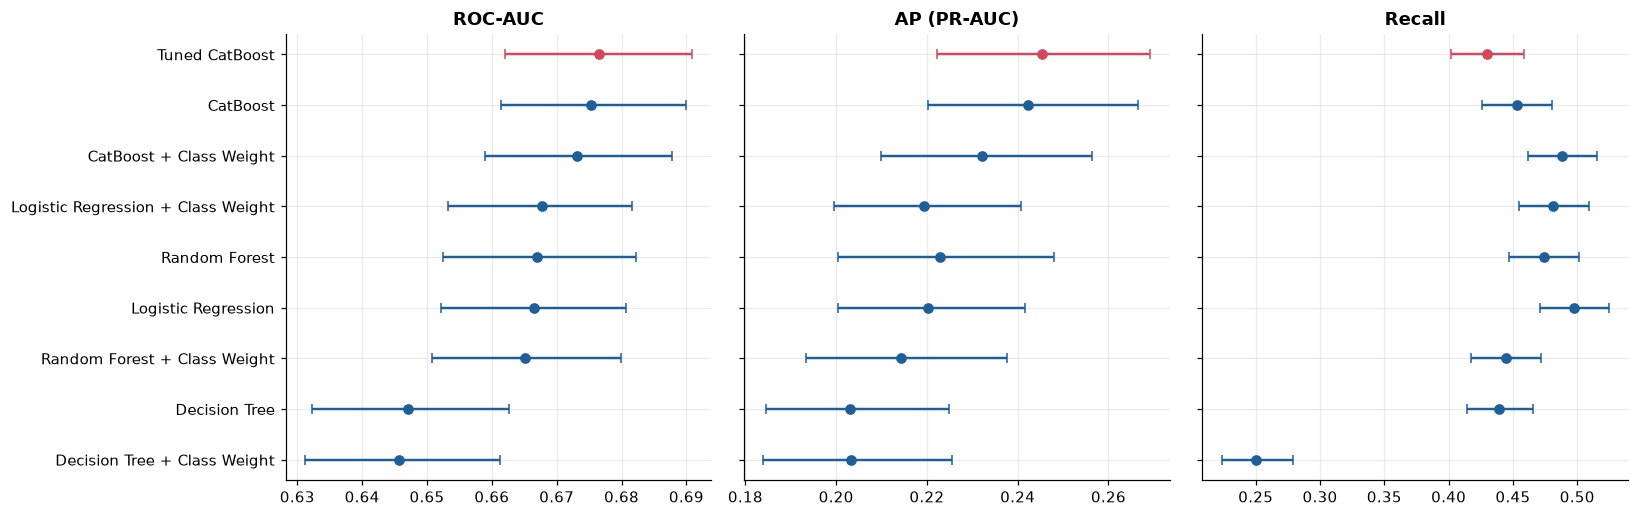

In [10]:
print(f"Patient-level bootstrap, {len(proba)} models x B = {N_BOOT:,} resamples (a few minutes) ...", flush=True)
draws = cluster_bootstrap_models(y, proba, thr_m, GI, N_BOOT, SEED)

rows = []
for name, pr in proba.items():
    est = _boot_metrics(y, pr, thr_m[name])
    d = {"Model": name, "Threshold": thr_m[name]}
    for m in ["ROC-AUC", "AP (PR-AUC)", "Recall", "Precision", "F1"]:
        d[m] = est[m]; d[m + " low"] = np.quantile(draws[name][m], 0.025); d[m + " high"] = np.quantile(draws[name][m], 0.975)
    rows.append(d)
cmp_tbl = pd.DataFrame(rows).sort_values("AP (PR-AUC)", ascending=False).reset_index(drop=True)

show = cmp_tbl[["Model", "Threshold"]].copy()
for m in ["ROC-AUC", "AP (PR-AUC)", "Recall", "Precision", "F1"]:
    show[m] = [f"{a:.3f} [{b:.3f}, {c:.3f}]" for a, b, c in zip(cmp_tbl[m], cmp_tbl[m + " low"], cmp_tbl[m + " high"])]
display(show.set_index("Model")); cmp_tbl.to_csv(TAB / "03_model_comparison_test.csv", index=False)
ev.plot_model_comparison(cmp_tbl, ["ROC-AUC", "AP (PR-AUC)", "Recall"], FIG / "03_model_comparison.png", highlight="Tuned CatBoost"); plt.show()

In [11]:
# paired patient-level bootstrap on the SAME resamples as the table above (no extra resampling needed)
pw = pairwise_cluster(y, proba, thr_m, draws, reference="Tuned CatBoost")
fmt = pw.copy()
for c in [c for c in fmt.columns if c.startswith("p ")]:
    fmt[c] = fmt[c].map(lambda v: "<0.001" if v < 0.001 else f"{v:.3f}")
display(fmt[["Model", "ΔAUC", "ΔAUC 95% CI", "p AUC (Holm)", "ΔAP", "ΔAP 95% CI", "p AP (Holm)", "ΔF1", "ΔF1 95% CI", "p F1 (Holm)",
             "ΔRecall", "p Recall (Holm)", "ΔSpecificity", "p Specificity (Holm)", "p DeLong (indep., reference) (Holm)"]].set_index("Model").round(4))
pw.to_csv(TAB / "03_pairwise_tests_vs_tuned_catboost.csv", index=False)

,ΔAUC,ΔAUC 95% CI,p AUC (Holm),ΔAP,ΔAP 95% CI,p AP (Holm),ΔF1,ΔF1 95% CI,p F1 (Holm),ΔRecall,p Recall (Holm),ΔSpecificity,p Specificity (Holm),"p DeLong (indep., reference) (Holm)"
Model,,,,,,,,,,,,,,
Logistic Regression,0.0099,"[+0.0046, +0.0152]",0.008,0.0250,"[+0.0163, +0.0336]",0.008,0.0078,"[-0.0008, +0.0166]",0.312,-0.0677,0.008,0.0633,0.008,<0.001
Decision Tree,0.0295,"[+0.0215, +0.0374]",0.008,0.0422,"[+0.0313, +0.0532]",0.008,0.0221,"[+0.0114, +0.0329]",0.008,-0.0099,0.282,0.0397,0.008,<0.001
Random Forest,0.0095,"[+0.0061, +0.0132]",0.008,0.0225,"[+0.0144, +0.0320]",0.008,0.0085,"[+0.0012, +0.0163]",0.162,-0.0447,0.008,0.0465,0.008,<0.001
CatBoost,0.0011,"[-0.0013, +0.0035]",0.370,0.0029,"[-0.0018, +0.0075]",0.231,0.0049,"[-0.0010, +0.0104]",0.312,-0.0235,0.008,0.0246,0.008,0.350
Logistic Regression + Class Weight,0.0087,"[+0.0034, +0.0139]",0.008,0.0259,"[+0.0172, +0.0349]",0.008,0.0078,"[-0.0009, +0.0164]",0.312,-0.0514,0.008,0.0507,0.008,0.003
Decision Tree + Class Weight,0.0308,"[+0.0231, +0.0387]",0.008,0.0420,"[+0.0314, +0.0522]",0.008,0.0455,"[+0.0305, +0.0605]",0.008,0.1796,0.008,-0.0938,0.008,<0.001
Random Forest + Class Weight,0.0114,"[+0.0077, +0.0153]",0.008,0.0311,"[+0.0215, +0.0408]",0.008,0.0087,"[-0.0000, +0.0175]",0.265,-0.0153,0.092,0.0238,0.008,<0.001
CatBoost + Class Weight,0.0033,"[-0.0002, +0.0070]",0.140,0.0131,"[+0.0063, +0.0201]",0.008,0.0041,"[-0.0035, +0.0124]",0.312,-0.0587,0.008,0.0504,0.008,0.147


**How to read it.** `Δ` = Tuned CatBoost minus the other model; a positive Δ with Holm-adjusted p < 0.05 means the tuned model is significantly better.
For F1, Recall and Specificity each model is used at its own threshold, so those rows mostly reflect different operating points rather than better ranking.
A non-significant gap means the improvement is within test-sampling noise, which is an honest and important finding for the Discussion section.
Bootstrap p-values cannot fall below about 2/(B+1) (= 0.001 for B = 2,000) before the Holm adjustment, so "0.008" after Holm simply means "smaller than every resample".

### Team's earlier validation / CV tables (kept for the report)

The modeling notebook reports Precision / Recall / F1 at a fixed threshold of 0.5 for every model. That is not comparable across models
(class-weighted models are centred near 0.5, the others are not), so those columns are labelled `@0.5` and must not be used to rank models;
use ROC-AUC / AP, or the table above, where every model uses its own validation-selected threshold.
The tuned CatBoost has no row in the team's tables, so one is added here (its CV AP is the best of 20 random-search draws and is therefore slightly optimistic).

In [13]:
from sklearn.metrics import roc_auc_score, average_precision_score

val_df = get_val_predictions()
yv, pv = val_df["y_true"].to_numpy(), val_df["probability"].to_numpy()
thr_chk = ev.best_f1_threshold(yv, pv)
print(f"F1-optimal threshold re-derived on the validation split: {thr_chk:.6f} | threshold saved by the modeling notebook: {THR:.6f}")
if abs(thr_chk - THR) > 1e-6:
    print("WARNING: the validation scores differ from the team's run (different library version / hardware?). "
          "Thresholds chosen below are still valid, but may not match the saved one exactly.")

# Sửa đường dẫn cv_results.csv về thư mục outputs/
cvr = pd.read_csv(ROOT / "outputs" / "cv_results.csv")
base_ap = (cvr["Mean CV AP"] / cvr["AP / Random Baseline"]).iloc[0]
tuned_cv = pd.DataFrame([{"Model": "Tuned CatBoost (best of 20 search draws)", "Mean CV AP": meta["best_cv_ap"], "Std CV AP": np.nan,
                          "AP / Random Baseline": meta["best_cv_ap"] / base_ap}])
display(pd.concat([cvr, tuned_cv], ignore_index=True).sort_values("Mean CV AP", ascending=False).reset_index(drop=True).round(4))

# Sửa đường dẫn validation_results.csv về thư mục outputs/
vr = pd.read_csv(ROOT / "outputs" / "validation_results.csv").rename(
    columns={"Precision": "Precision@0.5", "Recall": "Recall@0.5", "F1": "F1@0.5"})
t5 = ev.threshold_metrics(yv, pv, 0.5)
tuned_val = pd.DataFrame([{"Model": "Tuned CatBoost (added here)", "ROC-AUC": roc_auc_score(yv, pv), "AP": average_precision_score(yv, pv),
                           "Precision@0.5": t5["Precision"], "Recall@0.5": t5["Recall"], "F1@0.5": t5["F1"]}])
display(pd.concat([vr, tuned_val], ignore_index=True).sort_values("AP", ascending=False).reset_index(drop=True).round(4))

[cache] outputs/evaluation/val_predictions_tuned_catboost.csv exists - skipping refit (delete it to recompute)
F1-optimal threshold re-derived on the validation split: 0.135506 | threshold saved by the modeling notebook: 0.143588


,Model,Mean CV AP,Std CV AP,AP / Random Baseline
0,Tuned CatBoost (best of 20 search draws),0.2342,NaN,2.0482
1,CatBoost,0.2270,0.0052,1.9855
2,Random Forest,0.2192,0.0036,1.9169
3,CatBoost + Class Weight,0.2161,0.0022,1.8902
4,Random Forest + Class Weight,0.2109,0.0008,1.8446
5,Logistic Regression,0.2091,0.0031,1.8284
6,Logistic Regression + Class Weight,0.2073,0.0029,1.8132
7,Decision Tree,0.1920,0.0012,1.6789
8,Decision Tree + Class Weight,0.1899,0.0020,1.6608


,Model,ROC-AUC,AP,Precision@0.5,Recall@0.5,F1@0.5
0,Tuned CatBoost (added here),0.6776,0.2346,0.48,0.0067,0.0131
1,CatBoost,0.6779,0.2328,NaN,NaN,NaN
2,CatBoost + Class Weight,0.6690,0.2248,NaN,NaN,NaN
3,Random Forest,0.6753,0.2209,NaN,NaN,NaN
4,Logistic Regression,0.6653,0.2132,NaN,NaN,NaN
5,Decision Tree,0.6483,0.2122,NaN,NaN,NaN
6,Logistic Regression + Class Weight,0.6671,0.2120,NaN,NaN,NaN
7,Random Forest + Class Weight,0.6701,0.2071,NaN,NaN,NaN
8,Decision Tree + Class Weight,0.6437,0.2052,NaN,NaN,NaN


## 4. Threshold and cost-sensitive analysis

The default 0.5 threshold flags almost nobody when only 11% of patients are positive. The team chose **0.127** (max F1 on a validation split).
Below we (a) show the trade-off, (b) compare candidate operating points and (c) ask which threshold is best when a missed readmission
costs `k` times more than an unnecessary follow-up.

**No test-set tuning.** Every operating point other than the final one ("Recall >= x%", the cost-optimal thresholds) is chosen on the *validation* scores of the final model
(fit on 80% of train, same patient-grouped split as the modeling notebook) and then evaluated on the test set.
The thresholds that a search on the test set itself would pick are shown only as labelled oracle references.

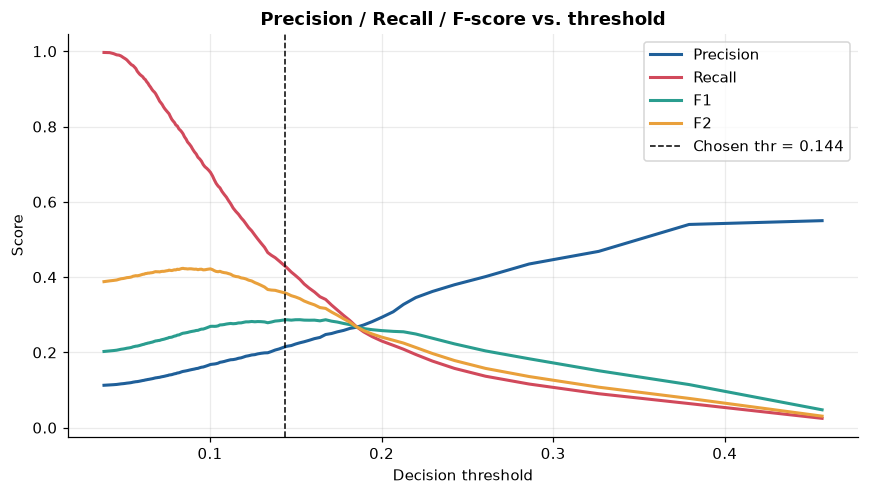

The final threshold 0.144 is the Bayes-optimal cut-off of an implied FN:FP cost ratio of about 6.0 (k = (1 - t) / t).


,Threshold,Recall,Precision,Specificity,F1,F2,Flagged %,TP,FP,FN,TN
Operating point,,,,,,,,,,,
Default 0.5,0.500,0.014,0.585,0.999,0.027,0.017,0.268,31,22,2185,17564
"Validation-selected, max F1 (FINAL)",0.144,0.430,0.215,0.802,0.286,0.358,22.371,952,3478,1264,14108
Recall >= 60% (threshold set on validation),0.113,0.586,0.181,0.666,0.276,0.405,36.224,1298,5875,918,11711
Recall >= 70% (threshold set on validation),0.096,0.697,0.162,0.545,0.263,0.420,48.167,1544,7994,672,9592
Recall >= 80% (threshold set on validation),0.081,0.797,0.146,0.411,0.246,0.421,61.241,1766,10361,450,7225
Test-optimal F1 (ORACLE - reference only),0.146,0.424,0.219,0.809,0.289,0.357,21.700,940,3357,1276,14229


In [14]:
sweep = ev.threshold_sweep(y, p)
ev.plot_threshold_sweep(sweep, THR, FIG / "04_threshold_sweep.png"); plt.show()

k_impl = (1 - THR) / THR
print(f"The final threshold {THR:.3f} is the Bayes-optimal cut-off of an implied FN:FP cost ratio of about {k_impl:.1f} (k = (1 - t) / t).")

ops = [("Default 0.5", 0.5),
       ("Validation-selected, max F1 (FINAL)", THR),
       ("Recall >= 60% (threshold set on validation)", ev.threshold_for_recall(yv, pv, 0.60)),
       ("Recall >= 70% (threshold set on validation)", ev.threshold_for_recall(yv, pv, 0.70)),
       ("Recall >= 80% (threshold set on validation)", ev.threshold_for_recall(yv, pv, 0.80)),
       ("Test-optimal F1 (ORACLE - reference only)", ev.best_f1_threshold(y, p))]
op_tbl = pd.DataFrame([{"Operating point": n, **ev.threshold_metrics(y, p, t)} for n, t in ops])
cols = ["Operating point", "Threshold", "Recall", "Precision", "Specificity", "F1", "F2", "Flagged %", "TP", "FP", "FN", "TN"]
display(op_tbl[cols].set_index("Operating point").round(3)); op_tbl[cols].to_csv(TAB / "04_operating_points.csv", index=False)

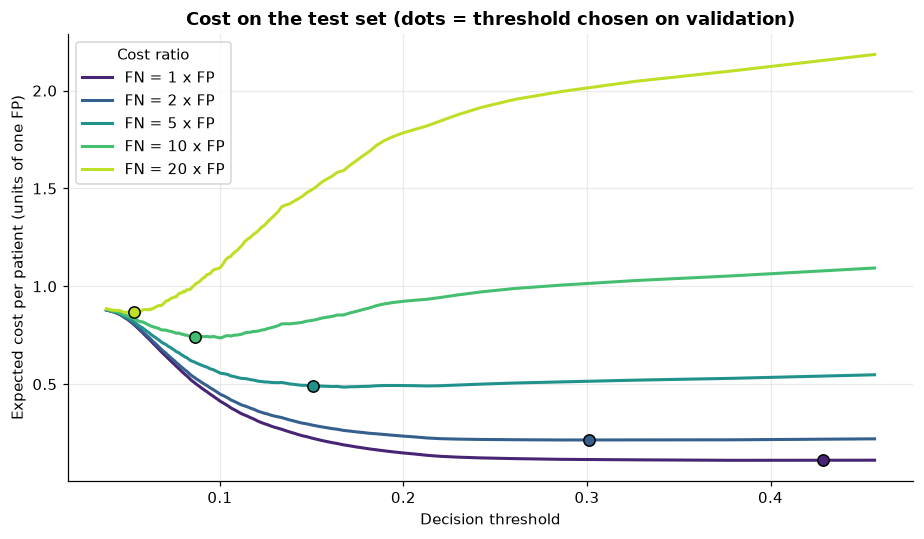

,Bayes thr,Optimal thr,Cost / patient,Treat-none cost,Treat-all cost,Saving vs best trivial %,Recall,Precision,Flagged %,Oracle thr (test),Oracle saving %
FN:FP cost ratio,,,,,,,,,,,
1,0.500,0.429,0.111,0.112,0.888,1.128,0.038,0.587,0.722,0.379,0.948
2,0.333,0.301,0.214,0.224,0.888,4.174,0.107,0.450,2.671,0.286,4.061
5,0.167,0.151,0.491,0.560,0.888,12.238,0.401,0.223,20.089,0.167,13.357
10,0.091,0.086,0.743,1.119,0.888,16.382,0.765,0.151,56.565,0.100,17.110
20,0.048,0.053,0.867,2.238,0.888,2.405,0.972,0.119,91.183,0.052,2.485


In [15]:
RATIOS = (1, 2, 5, 10, 20)
curves, oracle = ev.cost_analysis(y, p, RATIOS)        # grid search on the TEST set: kept only as an oracle reference + for the curves
n_te, pos_te = len(y), int(y.sum())
rows = []
for k in RATIOS:
    t_k = val_cost_threshold(yv, pv, k)                # threshold chosen on VALIDATION
    m = ev.threshold_metrics(y, p, t_k)                # ... and evaluated on TEST
    cost = (m["FP"] + k * m["FN"]) / n_te
    none, allc = k * pos_te / n_te, (n_te - pos_te) / n_te
    o = oracle[oracle["FN:FP cost ratio"] == k].iloc[0]
    rows.append({"FN:FP cost ratio": k, "Bayes thr": 1 / (1 + k), "Optimal thr": t_k, "Cost / patient": cost,
                 "Treat-none cost": none, "Treat-all cost": allc, "Saving vs best trivial %": 100 * (1 - cost / min(none, allc)),
                 "Recall": m["Recall"], "Precision": m["Precision"], "Flagged %": m["Flagged %"],
                 "Oracle thr (test)": o["Optimal thr"], "Oracle saving %": o["Saving vs best trivial %"]})
cs = pd.DataFrame(rows)
fig = ev.plot_cost_curves(curves, cs, None)
fig.axes[0].set_title("Cost on the test set (dots = threshold chosen on validation)")
fig.savefig(FIG / "04_cost_curves.png", dpi=200, bbox_inches="tight"); plt.show()
display(cs.round(3).set_index("FN:FP cost ratio")); cs.to_csv(TAB / "04_cost_sensitive_optimum.csv", index=False)

*Reading the table.* Cost is expressed in units of one false positive (an unnecessary follow-up call/visit); a false negative costs `k` units.
`Optimal thr` is chosen on the validation scores; `Cost / patient`, `Recall`, `Precision`, `Flagged %` and `Saving vs best trivial %` are measured on the test set.
`Oracle thr (test)` and `Oracle saving %` show what a grid search on the test set itself would give (an optimistic reference, not a valid result).
`Bayes thr = 1/(1+k)` is the theoretically optimal cut-off for perfectly calibrated probabilities; an empirical optimum close to it is consistent with
good calibration but does not prove it (calibration is assessed in Section 7).
`Saving vs best trivial` compares to the cheaper of "flag nobody" and "flag everybody": a model only adds value where this is clearly positive, and it can be negative when a validation-chosen threshold does not transfer.

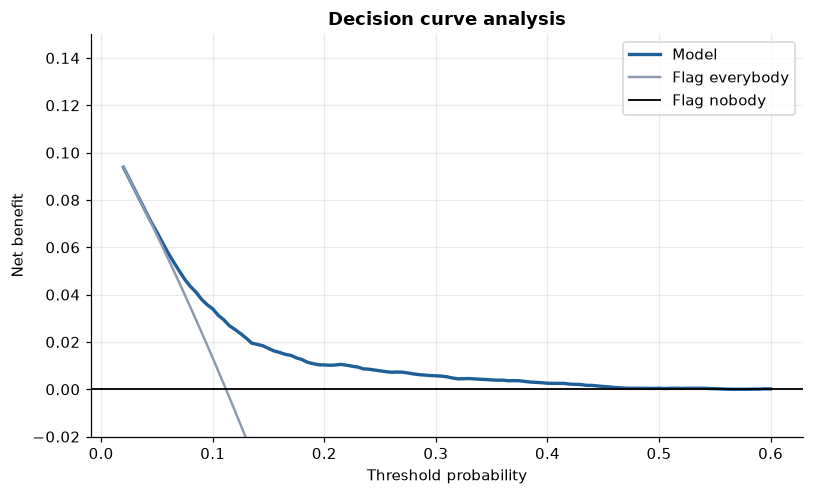

Net benefit exceeds both 'flag everybody' and 'flag nobody' (margin 0.001) for threshold probabilities 0.050 to 0.455 (contiguous: True); grid evaluated: 0.02 to 0.60.


In [16]:
dc = ev.decision_curve(y, p, np.linspace(0.02, 0.60, 117))
ev.plot_decision_curve(dc, FIG / "04_decision_curve.png"); plt.show()
dc.to_csv(TAB / "04_decision_curve.csv", index=False)

# explicit, reproducible rule: net benefit above BOTH trivial policies by a margin of 0.001
MARGIN = 0.001
beats = dc.loc[dc["Model"] > np.maximum(dc["Treat all"], 0.0) + MARGIN, "Threshold"]
DCA_LO, DCA_HI = float(beats.min()), float(beats.max())
contiguous = int(((dc["Threshold"] >= DCA_LO) & (dc["Threshold"] <= DCA_HI)).sum()) == len(beats)
print(f"Net benefit exceeds both 'flag everybody' and 'flag nobody' (margin {MARGIN}) for threshold probabilities "
      f"{DCA_LO:.3f} to {DCA_HI:.3f} (contiguous: {contiguous}); grid evaluated: {dc['Threshold'].min():.2f} to {dc['Threshold'].max():.2f}.")

## 5. Operational view: who should the hospital call first?

Hospitals can only intervene on a limited number of patients, so rank by predicted risk and look at what the top-k% captures.

,Patients flagged,Readmissions caught,Precision@k,Recall@k,Lift
Top %,,,,,
1,198,109,0.551,0.049,4.919
5,990,366,0.370,0.165,3.304
10,1980,554,0.280,0.250,2.500
20,3960,884,0.223,0.399,1.995
30,5941,1150,0.194,0.519,1.730
50,9901,1577,0.159,0.712,1.423


,n,Readmitted,Observed rate,Mean predicted,Lift,Cum. recall
Decile,,,,,,
1,1981,554,0.280,0.272,2.499,0.250
2,1981,331,0.167,0.170,1.493,0.399
3,1980,265,0.134,0.137,1.196,0.519
4,1980,234,0.118,0.116,1.056,0.625
5,1980,193,0.097,0.101,0.871,0.712
6,1980,174,0.088,0.088,0.785,0.790
7,1980,136,0.069,0.078,0.614,0.852
8,1980,141,0.071,0.068,0.636,0.915
9,1980,109,0.055,0.059,0.492,0.964


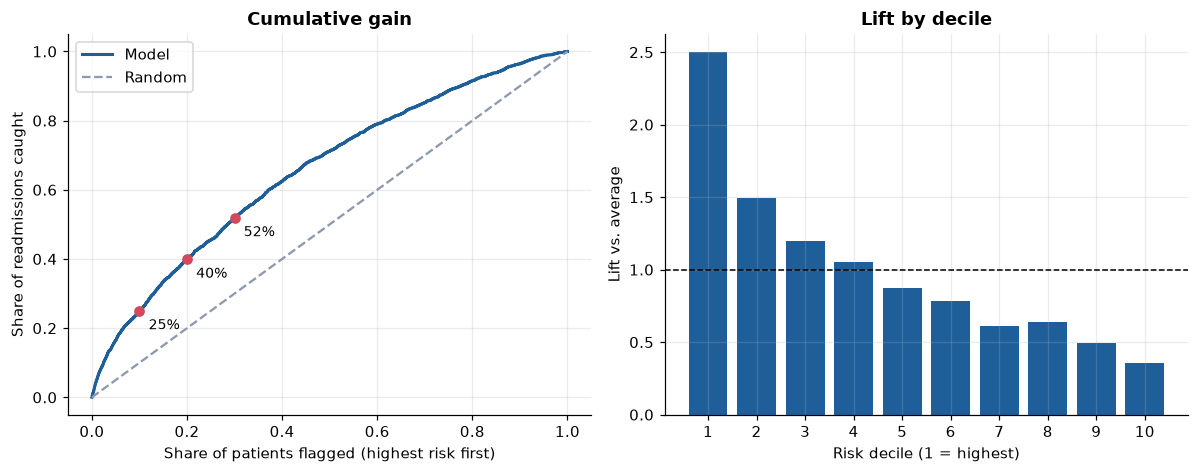

In [17]:
tk = ev.topk_table(y, p); display(tk.round(3).set_index("Top %")); tk.to_csv(TAB / "05_recall_at_topk.csv", index=False)
dt = ev.decile_table(y, p); display(dt.round(3).set_index("Decile")); dt.to_csv(TAB / "05_decile_table.csv", index=False)
ev.plot_gain_lift(y, p, FIG / "05_gain_lift.png"); plt.show()

## 6. Error analysis

Outcome labels at the final threshold: **TP** (caught), **FN** (missed readmission), **FP** (false alarm), **TN**.
Two comparisons answer two different questions:
* **FN vs TP** - why did the model miss some readmissions that look similar to the ones it caught?
* **FP vs TN** - what triggers false alarms?

Numeric features: Cohen's d (effect size) and Mann-Whitney p; categorical features: Cramér's V and chi-square p.
With ~20k rows almost every p-value is tiny, so **rank by effect size, not by p**.

The Mann-Whitney and chi-square p-values treat encounters as independent, so they are somewhat too small; this is one more reason to rank by effect size.

In [18]:
te = add_advanced_features(test.drop(columns="target")).copy()
te["inpatient_bin"] = pd.cut(te["number_inpatient"], [-1, 0, 1, 2, 100], labels=["0", "1", "2", "3+"])
pred_lbl = (p >= THR).astype(int)
out = ev.outcome_labels(y, pred_lbl)
te["outcome"], te["proba"], te["y"] = out, p, y
print(pd.Series(out).value_counts().to_string())

NUM = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_outpatient",
       "number_emergency", "number_inpatient", "number_diagnoses", "total_previous_visits"]
CAT = ["age", "gender", "race", "admission_type_id", "discharge_disposition_id", "admission_source_id", "payer_code",
       "medical_specialty", "diag_1_group", "diag_2_group", "diag_3_group", "insulin", "change", "diabetesMed", "A1Cresult", "max_glu_serum"]
fn_num, fn_cat = ev.compare_groups(te, out == "FN", out == "TP", NUM, CAT, "FN", "TP")
fp_num, fp_cat = ev.compare_groups(te, out == "FP", out == "TN", NUM, CAT, "FP", "TN")
print("\n=== Missed (FN) vs caught (TP) readmissions - numeric ==="); display(fn_num.round(3))
print("=== Missed (FN) vs caught (TP) - categorical (top 8 by Cramér V) ==="); display(fn_cat.head(8).round(3))
print("=== False alarms (FP) vs correct negatives (TN) - numeric ==="); display(fp_num.round(3))
print("=== False alarms (FP) vs correct negatives (TN) - categorical (top 8) ==="); display(fp_cat.head(8).round(3))
for n, d in [("06_fn_vs_tp_numeric", fn_num), ("06_fn_vs_tp_categorical", fn_cat), ("06_fp_vs_tn_numeric", fp_num), ("06_fp_vs_tn_categorical", fp_cat)]:
    d.to_csv(TAB / f"{n}.csv", index=False)

TN    14108
FP     3478
FN     1264
TP      952

=== Missed (FN) vs caught (TP) readmissions - numeric ===


,Feature,Mean FN,Mean TP,Cohen d,p (Mann-Whitney)
0,number_inpatient,0.242,2.277,-1.622,0.000
1,total_previous_visits,0.664,3.231,-1.298,0.000
2,number_emergency,0.107,0.492,-0.557,0.000
3,num_procedures,1.517,1.183,0.199,0.007
4,num_medications,16.267,17.783,-0.195,0.000
5,number_diagnoses,7.567,7.879,-0.182,0.000
6,time_in_hospital,4.572,5.075,-0.165,0.000
7,number_outpatient,0.315,0.462,-0.156,0.000
8,num_lab_procedures,43.216,44.822,-0.083,0.064


=== Missed (FN) vs caught (TP) - categorical (top 8 by Cramér V) ===


,Feature,Cramér V,p (chi2),Most different level,% FN,% TP
0,discharge_disposition_id,0.383,0.000,1,60.047,33.824
1,medical_specialty,0.206,0.000,Unknown,52.294,47.164
2,diag_1_group,0.198,0.000,Diabetes,7.832,13.445
3,age,0.157,0.000,[20-30),0.870,5.147
4,diag_3_group,0.144,0.001,Circulatory,30.142,23.950
5,diag_2_group,0.143,0.001,Circulatory,34.573,27.416
6,payer_code,0.135,0.000,SP,5.459,2.836
7,insulin,0.125,0.000,No,45.174,36.765


=== False alarms (FP) vs correct negatives (TN) - numeric ===


,Feature,Mean FP,Mean TN,Cohen d,p (Mann-Whitney)
0,number_inpatient,1.922,0.194,2.243,0.0
1,total_previous_visits,2.840,0.545,1.665,0.0
2,number_emergency,0.395,0.086,0.652,0.0
3,number_diagnoses,8.044,7.214,0.433,0.0
4,time_in_hospital,5.152,4.127,0.349,0.0
5,num_medications,17.731,15.292,0.319,0.0
6,number_outpatient,0.523,0.264,0.294,0.0
7,num_lab_procedures,45.514,41.907,0.185,0.0
8,num_procedures,1.117,1.402,-0.167,0.0


=== False alarms (FP) vs correct negatives (TN) - categorical (top 8) ===


,Feature,Cramér V,p (chi2),Most different level,% FP,% TN
0,discharge_disposition_id,0.387,0.0,1,34.704,69.053
1,medical_specialty,0.144,0.0,Cardiology,1.553,6.167
2,insulin,0.144,0.0,No,37.464,50.539
3,diag_3_group,0.122,0.0,Diabetes,13.197,18.238
4,age,0.122,0.0,[50-60),11.702,19.181
5,diag_2_group,0.116,0.0,Diabetes,9.459,13.680
6,diag_1_group,0.103,0.0,Respiratory,10.926,14.665
7,admission_source_id,0.100,0.0,7,62.680,54.423


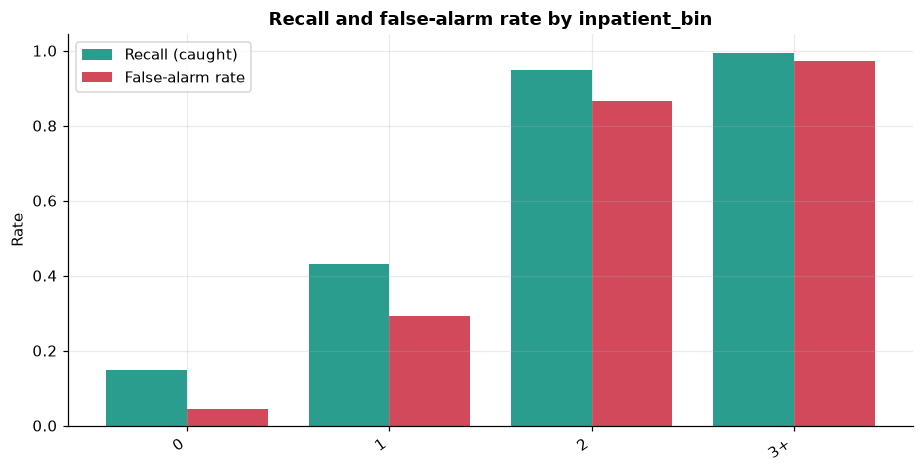

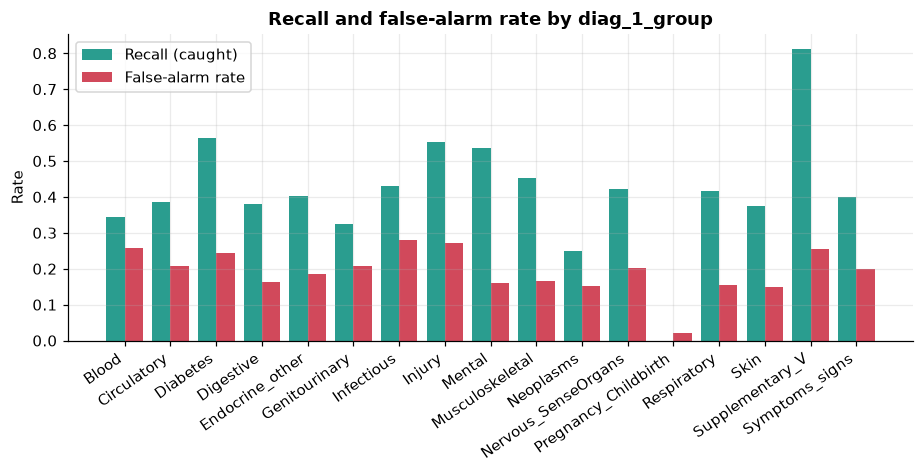

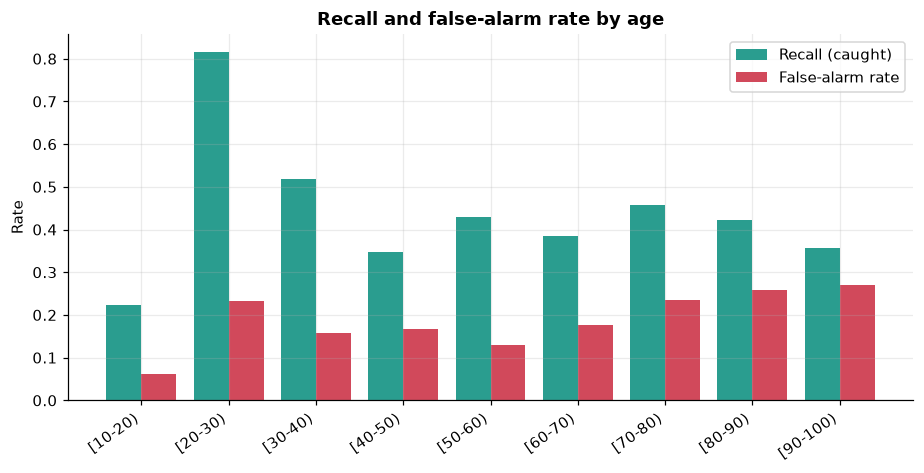

In [19]:
order_age = sorted(te["age"].unique())
ev.plot_error_rate_by(te, y, pred_lbl, "inpatient_bin", ["0", "1", "2", "3+"], FIG / "06_error_by_prior_inpatient.png"); plt.show()
ev.plot_error_rate_by(te, y, pred_lbl, "diag_1_group", None, FIG / "06_error_by_diag1.png"); plt.show()
ev.plot_error_rate_by(te, y, pred_lbl, "age", order_age, FIG / "06_error_by_age.png"); plt.show()

In [20]:
# Most confident mistakes (concrete examples for the report; candidates for local explanations if a SHAP section is added)
cols_show = ["proba", "age", "gender", "time_in_hospital", "number_inpatient", "number_emergency", "num_medications", "discharge_disposition_id", "diag_1_group"]
print("Missed readmissions the model was MOST sure were safe (lowest score among FN):"); display(te[te.outcome == "FN"].nsmallest(5, "proba")[cols_show].round(3))
print("False alarms the model was MOST sure about (highest score among FP):"); display(te[te.outcome == "FP"].nlargest(5, "proba")[cols_show].round(3))

Missed readmissions the model was MOST sure were safe (lowest score among FN):


,proba,age,gender,time_in_hospital,number_inpatient,number_emergency,num_medications,discharge_disposition_id,diag_1_group
16051,0.031,[50-60),Male,1,0,0,9,1,Musculoskeletal
14747,0.037,[40-50),Male,2,0,0,5,1,Diabetes
13947,0.037,[10-20),Female,3,0,0,3,1,Diabetes
568,0.037,[0-10),Male,2,0,0,5,1,Diabetes
6858,0.037,[50-60),Male,1,0,0,3,1,Digestive


False alarms the model was MOST sure about (highest score among FP):


,proba,age,gender,time_in_hospital,number_inpatient,number_emergency,num_medications,discharge_disposition_id,diag_1_group
10598,0.645,[60-70),Male,3,6,0,11,1,Supplementary_V
2831,0.627,[50-60),Female,13,3,0,24,2,Mental
18153,0.595,[40-50),Female,12,3,1,27,2,Mental
16010,0.594,[60-70),Male,3,2,0,19,22,Circulatory
10676,0.582,[80-90),Female,3,6,0,22,1,Respiratory


## 7. Calibration and subgroup performance

**Calibration** asks whether "20% risk" really means 20% of such patients are readmitted. It matters because hospitals will use the
probabilities themselves, not just the ranking. Slope = 1 and intercept = 0 are ideal; slope < 1 means over-confident.

(The per-bin intervals in the calibration table use a normal approximation that treats encounters as independent, so they are slightly narrow.)

,value
ECE,0.0042
Cal. slope,1.0883
Cal. intercept (fit),0.1519
Mean predicted,0.1135
Observed rate,0.1119
Offset (logit),-0.0164


,n,mean_pred,obs_rate,ci_low,ci_high
0,1981,0.0468,0.0399,0.0313,0.0485
1,1980,0.0591,0.0551,0.0450,0.0651
2,1980,0.0684,0.0712,0.0599,0.0825
3,1980,0.0778,0.0687,0.0575,0.0798
4,1980,0.0882,0.0879,0.0754,0.1003
5,1980,0.1006,0.0975,0.0844,0.1105
6,1980,0.1157,0.1182,0.1040,0.1324
7,1980,0.1371,0.1338,0.1188,0.1488
8,1980,0.1697,0.1672,0.1507,0.1836
9,1981,0.2721,0.2797,0.2599,0.2994


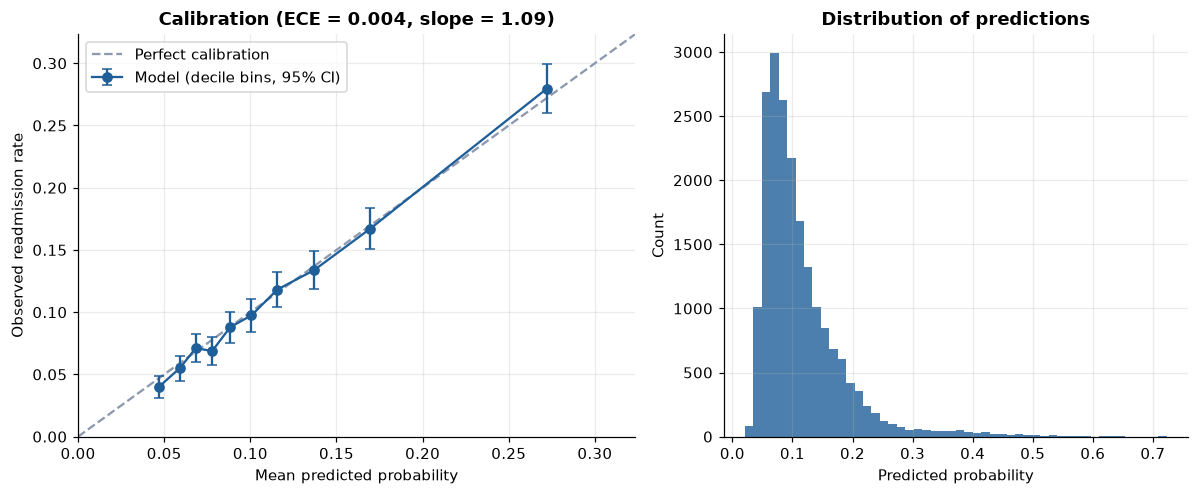

In [21]:
cal = ev.calibration_summary(y, p); display(pd.Series(cal, name="value").round(4).to_frame())
ct = ev.calibration_table(y, p); display(ct.round(4)); ct.to_csv(TAB / "07_calibration_bins.csv", index=False)
pd.Series(cal, name="value").to_csv(TAB / "07_calibration_summary.csv", index_label="metric")
ev.plot_calibration(y, p, path=FIG / "07_calibration.png"); plt.show()

**Subgroups / fairness.** A model with a decent overall AUC can still fail specific groups. Reported per group: ROC-AUC, Recall, false-positive rate,
prevalence. Groups with fewer than 500 rows or 50 positives are listed but flagged `Reliable = False`, have no interval, and are excluded from the plots and the gap summary
(their AUCs are too noisy to interpret). Intervals for AUC, Recall and prevalence come from a patient-level cluster bootstrap inside each reliable group (B = 1,000).
**Note** that Recall / false-positive differences between groups partly reflect different base rates under one global threshold; they flag where to look, they are not proof of unfair treatment.

,Gap ROC-AUC,Gap Recall,Gap FPR
Feature,,,
age,0.195,0.173,0.140
gender,0.011,0.054,0.022
race,0.010,0.001,0.023
admission_type_id,0.029,0.044,0.065
discharge_disposition_id,0.082,0.202,0.276
diag_1_group,0.157,0.314,0.129
inpatient_bin,0.062,0.847,0.926


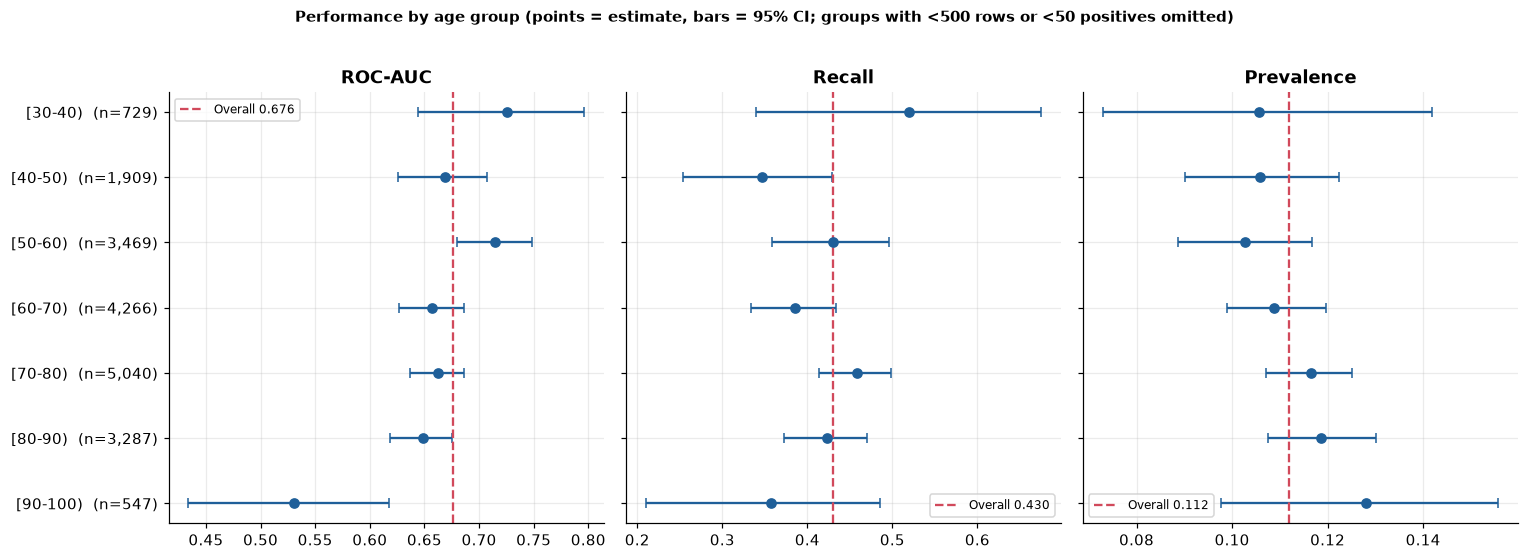

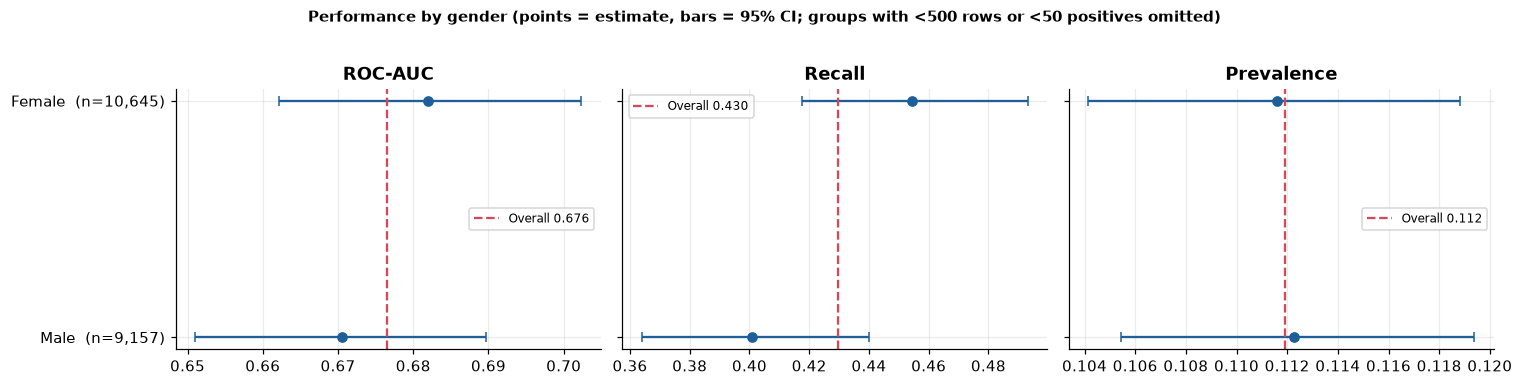

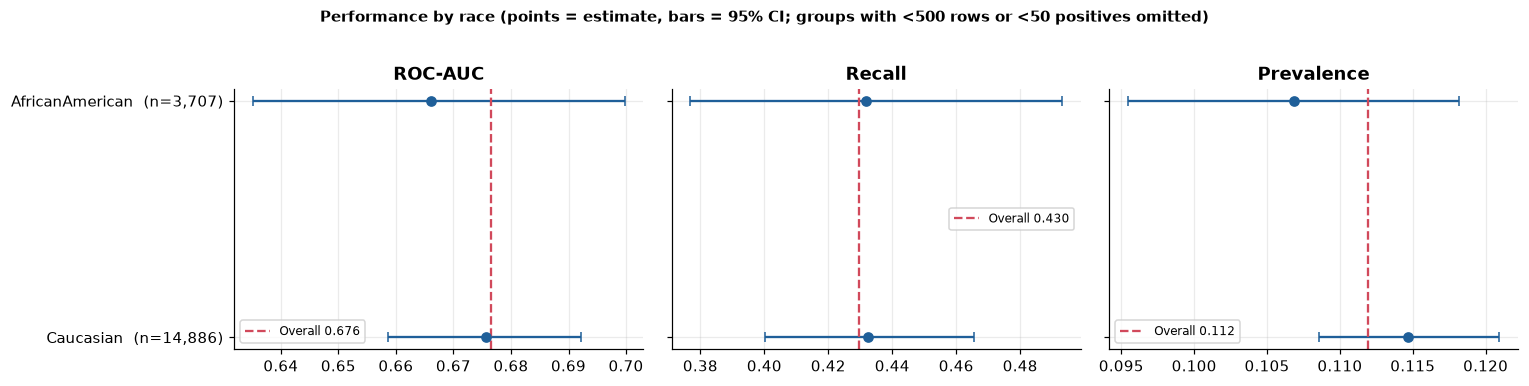

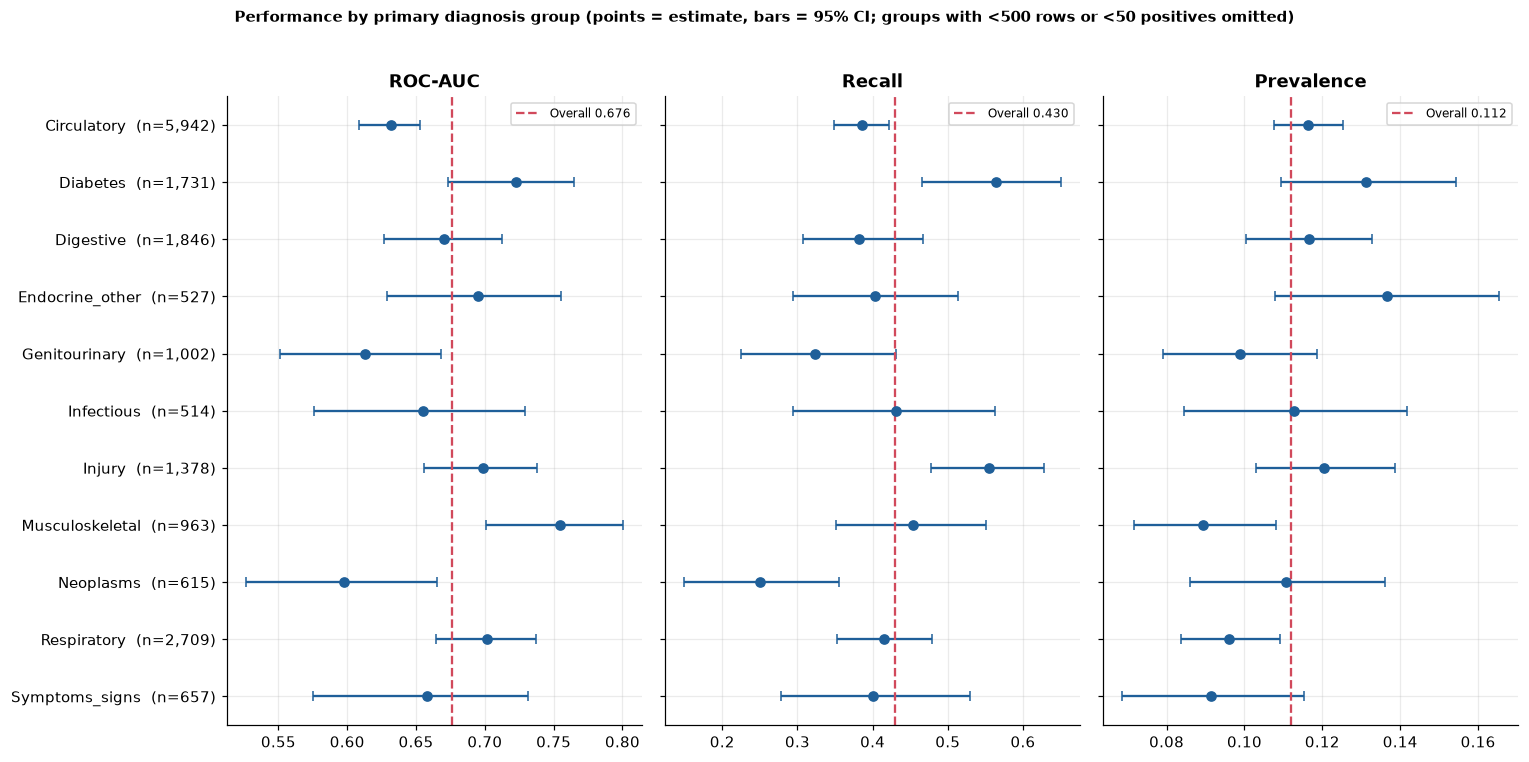

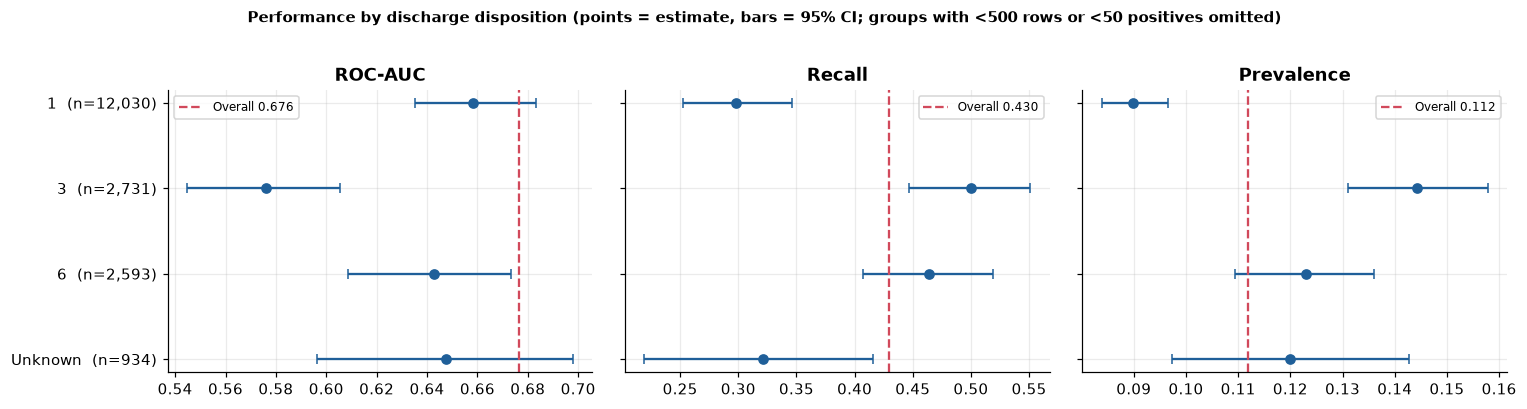

In [22]:
sg_cols = ["age", "gender", "race", "admission_type_id", "discharge_disposition_id", "diag_1_group", "inpatient_bin"]  # reliable = n>=500 and >=50 positives
overall = {"ROC-AUC": auc, "Recall": tm["Recall"], "Prevalence": prev}
reports, gaps = [], []
for c in sg_cols:
    rep = subgroup_report_cluster(te, y, p, THR, c, GROUPS, N_BOOT_SG, SEED); reports.append(rep)
    g = ev.subgroup_gaps(rep); gaps.append({"Feature": c, **{f"Gap {k}": v for k, v in g.items()}})
sg = pd.concat(reports, ignore_index=True)
gap_tbl = pd.DataFrame(gaps)
display(gap_tbl.round(3).set_index("Feature"))
sg.to_csv(TAB / "07_subgroup_performance.csv", index=False); gap_tbl.to_csv(TAB / "07_subgroup_gaps.csv", index=False)
for c, label in [("age", "age group"), ("gender", "gender"), ("race", "race"), ("diag_1_group", "primary diagnosis group"), ("discharge_disposition_id", "discharge disposition")]:
    ev.plot_subgroups(sg[sg.Feature == c], label, overall, FIG / f"07_subgroup_{c}.png"); plt.show()

In [23]:
keep = ["Group", "n", "Positives", "Prevalence", "ROC-AUC", "AUC low", "AUC high", "Recall", "Recall low", "Recall high", "FPR", "Flagged %"]
for f in ["age", "gender", "race", "inpatient_bin"]:
    print(f"--- {f} (reliable groups only)"); display(sg[(sg.Feature == f) & sg.Reliable][keep].round(3).reset_index(drop=True))

--- age (reliable groups only)


,Group,n,Positives,Prevalence,ROC-AUC,AUC low,AUC high,Recall,Recall low,Recall high,FPR,Flagged %
0,[70-80),5040,587,0.116,0.663,0.637,0.686,0.458,0.414,0.498,0.235,26.131
1,[60-70),4266,464,0.109,0.657,0.627,0.686,0.386,0.334,0.434,0.177,19.972
2,[50-60),3469,356,0.103,0.715,0.679,0.748,0.430,0.359,0.496,0.131,16.143
3,[80-90),3287,390,0.119,0.648,0.618,0.675,0.423,0.373,0.471,0.258,27.776
4,[40-50),1909,202,0.106,0.669,0.626,0.708,0.347,0.254,0.429,0.168,18.649
5,[30-40),729,77,0.106,0.726,0.644,0.796,0.519,0.340,0.675,0.158,19.616
6,[90-100),547,70,0.128,0.531,0.434,0.618,0.357,0.210,0.485,0.270,28.154


--- gender (reliable groups only)


,Group,n,Positives,Prevalence,ROC-AUC,AUC low,AUC high,Recall,Recall low,Recall high,FPR,Flagged %
0,Female,10645,1188,0.112,0.682,0.662,0.702,0.455,0.417,0.493,0.208,23.532
1,Male,9157,1028,0.112,0.671,0.651,0.690,0.401,0.364,0.440,0.186,21.022


--- race (reliable groups only)


,Group,n,Positives,Prevalence,ROC-AUC,AUC low,AUC high,Recall,Recall low,Recall high,FPR,Flagged %
0,Caucasian,14886,1707,0.115,0.676,0.659,0.692,0.432,0.400,0.466,0.198,22.451
1,AfricanAmerican,3707,396,0.107,0.666,0.635,0.700,0.432,0.377,0.493,0.221,24.332


--- inpatient_bin (reliable groups only)


,Group,n,Positives,Prevalence,ROC-AUC,AUC low,AUC high,Recall,Recall low,Recall high,FPR,Flagged %
0,0,13277,1142,0.086,0.643,0.626,0.660,0.147,0.127,0.168,0.045,5.400
1,1,3775,484,0.128,0.613,0.587,0.638,0.430,0.386,0.473,0.291,30.914
2,2,1444,236,0.163,0.587,0.548,0.627,0.949,0.920,0.975,0.865,87.881
3,3+,1306,354,0.271,0.649,0.602,0.689,0.994,0.986,1.000,0.972,97.779


## 8. Comparison with public / published baselines

**Important caveat.** The numbers below were taken from the cited pages and are *not* re-run by us. Splits, preprocessing,
class balancing and the definition of the positive class can differ, so they are an orientation, not a controlled head-to-head.
The only controlled comparison is Section 3 (same split, same rows). Whether each source split by patient has not been verified, so that column reads
"Not verified" until the source has been opened and checked; the ROC-AUC values of the sources have not been re-checked either.

In [24]:
mine = ev.ranking_metrics(y, p)
baselines = pd.DataFrame([
    # source, model, ROC-AUC, AP, note  (None = not reported)
    ("Emi-Johnson & Nkrumah 2025 (Cureus)", "XGBoost",                        0.667, None, "paper, DOI 10.7759/cureus.82437; value as cited, not re-checked"),
    ("Emi-Johnson & Nkrumah 2025 (Cureus)", "Logistic Regression",            0.642, None, "paper, DOI 10.7759/cureus.82437; value as cited, not re-checked"),
    ("Emi-Johnson & Nkrumah 2025 (Cureus)", "Random Forest",                  0.630, None, "paper, DOI 10.7759/cureus.82437; value as cited, not re-checked"),
    ("GitHub: chaitra-satheesh",            "LogReg + RandomOverSampler",     0.649, 0.209, "repo README; value as cited, not re-checked"),
    ("GitHub: brunoarine/diabetes",         "Random Forest",                  0.66,  None, "repo README; value as cited, not re-checked"),
    ("GitHub: brunoarine/diabetes",         "Logistic Regression",            0.64,  None, "repo README; value as cited, not re-checked"),
    ("GitHub: avithekkc",                   "Random Forest (recall-focused)", 0.674, None, "repo README; value as cited, not re-checked"),
], columns=["Source", "Model", "ROC-AUC", "AP", "Note"])
baselines["Split by patient?"] = "Not verified"
ours = pd.DataFrame([{"Source": "This work (patient-grouped split)", "Model": "Tuned CatBoost", "ROC-AUC": mine["ROC-AUC"],
                      "AP": mine["AP (PR-AUC)"], "Note": f"95% CI AUC [{lo:.3f}, {hi:.3f}] (patient-level bootstrap)", "Split by patient?": "Yes"}])
bl = pd.concat([baselines, ours], ignore_index=True)
display(bl.round(3)); bl.to_csv(TAB / "08_external_baselines.csv", index=False)

,Source,Model,ROC-AUC,AP,Note,Split by patient?
0,Emi-Johnson & Nkrumah 2025 (Cureus),XGBoost,0.667,NaN,"paper, DOI 10.7759/cureus.82437; value as cite...",Not verified
1,Emi-Johnson & Nkrumah 2025 (Cureus),Logistic Regression,0.642,NaN,"paper, DOI 10.7759/cureus.82437; value as cite...",Not verified
2,Emi-Johnson & Nkrumah 2025 (Cureus),Random Forest,0.630,NaN,"paper, DOI 10.7759/cureus.82437; value as cite...",Not verified
3,GitHub: chaitra-satheesh,LogReg + RandomOverSampler,0.649,0.209,"repo README; value as cited, not re-checked",Not verified
4,GitHub: brunoarine/diabetes,Random Forest,0.660,NaN,"repo README; value as cited, not re-checked",Not verified
5,GitHub: brunoarine/diabetes,Logistic Regression,0.640,NaN,"repo README; value as cited, not re-checked",Not verified
6,GitHub: avithekkc,Random Forest (recall-focused),0.674,NaN,"repo README; value as cited, not re-checked",Not verified
7,This work (patient-grouped split),Tuned CatBoost,0.676,0.245,"95% CI AUC [0.662, 0.691] (patient-level boots...",Yes


## 9. Key numbers for the report (auto-generated)

In [25]:
k5 = cs[cs["FN:FP cost ratio"] == 5].iloc[0]; k10 = cs[cs["FN:FP cost ratio"] == 10].iloc[0]
t10 = tk[tk["Top %"] == 10].iloc[0]; t20 = tk[tk["Top %"] == 20].iloc[0]
lines = [
 f"ROC-AUC {auc:.3f} (95% patient-level bootstrap CI {lo:.3f}-{hi:.3f}); AP {r['AP (PR-AUC)']:.3f} = {r['AP / prevalence']:.2f}x the random baseline of {prev:.3f}.",
 f"At the validation-selected threshold {THR:.3f} (implied FN:FP cost ratio about {k_impl:.1f}): Recall {tm['Recall']:.3f}, Precision {tm['Precision']:.3f}, F1 {tm['F1']:.3f}; {tm['Flagged %']:.1f}% of patients flagged.",
 f"Top 10% highest-risk patients: {t10['Precision@k']:.1%} are readmitted (lift {t10['Lift']:.2f}) and capture {t10['Recall@k']:.1%} of all readmissions; top 20% capture {t20['Recall@k']:.1%}.",
 f"Calibration: ECE {cal['ECE']:.3f}, slope {cal['Cal. slope']:.2f}.",
 f"Cost-sensitive (thresholds chosen on validation, evaluated on test): with FN = 5xFP the threshold is {k5['Optimal thr']:.3f} (test saving {k5['Saving vs best trivial %']:.1f}% vs best trivial policy); with FN = 10xFP it is {k10['Optimal thr']:.3f} (saving {k10['Saving vs best trivial %']:.1f}%).",
 f"Decision curve: net benefit exceeds both trivial policies (margin {MARGIN}) for threshold probabilities {DCA_LO:.3f}-{DCA_HI:.3f} (grid up to {dc['Threshold'].max():.2f}).",
 f"Uncertainty: patient-level cluster bootstrap over {n_pat:,} test patients, B = {N_BOOT:,} (subgroups B = {N_BOOT_SG:,}).",
]
display(Markdown("\n".join("- " + l for l in lines)))
(TAB / "09_key_numbers.txt").write_text("\n".join(lines))

- ROC-AUC 0.676 (95% patient-level bootstrap CI 0.662-0.691); AP 0.245 = 2.19x the random baseline of 0.112.
- At the validation-selected threshold 0.144 (implied FN:FP cost ratio about 6.0): Recall 0.430, Precision 0.215, F1 0.286; 22.4% of patients flagged.
- Top 10% highest-risk patients: 28.0% are readmitted (lift 2.50) and capture 25.0% of all readmissions; top 20% capture 39.9%.
- Calibration: ECE 0.004, slope 1.09.
- Cost-sensitive (thresholds chosen on validation, evaluated on test): with FN = 5xFP the threshold is 0.151 (test saving 12.2% vs best trivial policy); with FN = 10xFP it is 0.086 (saving 16.4%).
- Decision curve: net benefit exceeds both trivial policies (margin 0.001) for threshold probabilities 0.050-0.455 (grid up to 0.60).
- Uncertainty: patient-level cluster bootstrap over 13,998 test patients, B = 2,000 (subgroups B = 1,000).

849